# HOMEWORK 14

Done by: **Bohdan Pinchuk**

Link: https://github.com/BogdanPinchuk/ComputerVision-PBY_HW14

In this homework you are going to build your first classifier for the CIFAR-10 dataset. This dataset contains 10 different classes and you can learn more about it [here](https://www.cs.toronto.edu/~kriz/cifar.html). This homework consists of the following tasks:
* Dataset inspection
* Building the network
* Training
* Evaluation

At the end, as usual, there will be a couple of questions for you to answer :-)

In [1]:
# # Silent installation or update
#
# import sys
# from packaging.requirements import Requirement
# from importlib.metadata import PackageNotFoundError, version
#
# # Clean cache
# !"{sys.executable}" -m pip cache purge -q
#
# # Force updating
# package_update = [
#     "pip",
#     "scikit-learn",
#     "pandas",
# ]
#
# for package_name in package_update:
#     !"{sys.executable}" -m pip install -U "{package_name}" -q
#
# # Install missing packages
# package_array = [
#     "jinja2",
#     "ipywidgets",
#     "nbformat",
#     "numpy",
#     "matplotlib",
#     "opencv-contrib-python",
#     "torch",
#     "keras",
#     "pydot",
#     "pydotplus",
# ]
#
#
# def is_package_satisfied(req_str: str) -> bool:
#     try:
#         req = Requirement(req_str)
#         installed_ver = version(req.name)
#         if req.specifier:
#             return installed_ver in req.specifier
#         return True
#     except PackageNotFoundError:
#         return False
#
#
# for package_name in package_array:
#     if not is_package_satisfied(package_name):
#         !"{sys.executable}" -m pip install "{package_name}" -q


In [2]:
# # Synchronization with remote source
#
# import shutil
# from pathlib import Path
#
# # Input data
# hm_version = 14
#
# # Solution
# git_project_url = f"https://github.com/BogdanPinchuk/ComputerVision-PBY_HW{hm_version}.git"
# main_file_name = f"Bohdan_Pinchuk_CV_HW{hm_version}.ipynb"
#
# # upload all files
# current_path = !pwd
# current_path = current_path[0]
# parent_path = !dirname "$current_path"
# parent_path = parent_path[0]
# temp_path = f"{parent_path}/temp"
#
# # Clone data
# !rm -rf "$temp_path"
# !git clone "$git_project_url" "$temp_path"
#
# source = Path(temp_path)
# destination = Path(current_path)
# exclude = {main_file_name, ".git", ".idea"}
#
# for item in source.iterdir():
#     if item.name in exclude:
#         continue
#
#     target = destination / item.name
#     if item.is_dir():
#         shutil.copytree(item, target, dirs_exist_ok=True)
#     else:
#         shutil.copy2(item, target)
#
# # Clean temp folder
# !rm -rf "$temp_path"
#
# # Note. To upload big files to GitHub, execute the next command in the terminal
# # 1. brew install git-lfs
# # 2. git lfs install
# # 3.1. git lfs track "*.safetensors"
# # 3.2. git lfs track "*.bin"

### Step 0: Dataset Inspection

Load the dataset and make a quick inspection.

In [3]:
# Downloading data

import os

# has to be set before keras is imported
os.environ['KERAS_BACKEND'] = 'torch'
os.environ['KERAS_HOME'] = os.path.abspath('resources/data')
import keras
import numpy as np
from pathlib import Path
import apps.reporter as rpt

# Input data
n_images_per_class = 3
rng_seed = 42
folder_name = "resources/data"

# Solution
folder_path = Path(folder_name)
folder_path.mkdir(parents=True, exist_ok=True)

# Set the seed for reproducibility (python, numpy and the backend)
keras.utils.set_random_seed(rng_seed)
np.random.seed(rng_seed)

# Load the dataset
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
# The labels come as (N, 1) arrays, flatten them to (N,)
y_train, y_test = y_train.flatten(), y_test.flatten()

# analysis image
example_img = x_train[0]

# Mapping from class ID to class name
classes = {0: 'plane', 1: 'car', 2: 'bird', 3: 'cat', 4: 'deer', 5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'}

preview_samples = []
# preparing set of images for showing
for class_id in range(len(classes)):
    # filter indexes of the necessary class
    class_indices = np.where(y_train == class_id)[0]
    # get 3 random images
    random_indices = np.random.choice(class_indices, size=n_images_per_class, replace=False)
    # add images to list
    for idx in random_indices:
        preview_samples.append((classes[class_id], x_train[idx]))

rp = rpt.Reporter()
rp.add_item("Dataset directory", folder_name)
rp.add_item("Image: (rows, cols, channels)", str(example_img.shape))
rp.add_item("Pixel value range", f"[{x_train.min()}, {x_train.max()}] ({x_train.dtype})")
rp.add_item("Number of items in the train dataset", f"{len(y_train)} samples")
rp.add_item("Number of items in the test dataset", f"{len(y_test)} samples")
rp.add_item("Count of classes", str(len(classes)))
for key, value in classes.items():
    rp.add_item(f"Class: {value}", f"id: {key}")

# Print results
rp.print_pd_report("Report of CIFAR-10 Dataset Inspection")


Attribute,Result
Dataset directory,resources/data
"Image: (rows, cols, channels)","(32, 32, 3)"
Pixel value range,"[0, 255] (uint8)"
Number of items in the train dataset,50000 samples
Number of items in the test dataset,10000 samples
Count of classes,10
Class: plane,id: 0
Class: car,id: 1
Class: bird,id: 2
Class: cat,id: 3


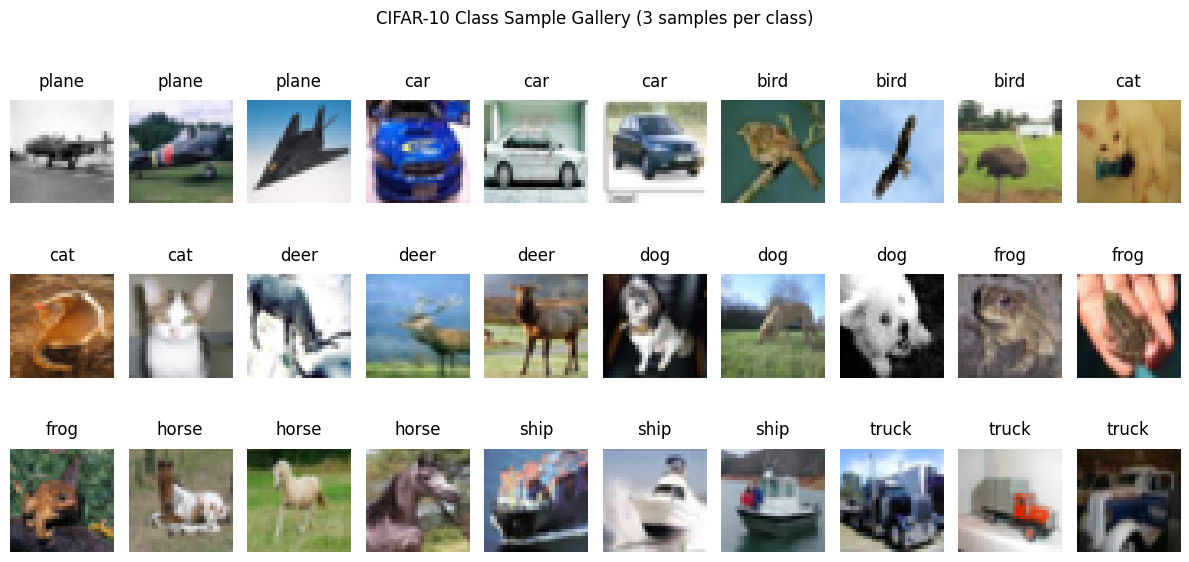

In [4]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_img_cols = 10
images_list = preview_samples
n_img_rows = math.ceil(len(images_list) / n_img_cols)

# Solution
_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 2 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_list):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color='black')
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_list), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("CIFAR-10 Class Sample Gallery (3 samples per class)", y=1.0)
plt.tight_layout()
plt.show()


Compute the class histogram (you can visualize it if you want). Is the dataset balanced?

Hint: You might find [Counter](https://docs.python.org/3/library/collections.html#collections.Counter) tool useful. In any case, it's up to you how you compute the histogram.

In [5]:
# Compute the class histogram

import numpy as np
import apps.reporter as rpt

# Input data

# Solution
class_names = list(classes.values())

# calculate count of each classes
train_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)

# check balancing
is_train_balanced = len(set(train_counts)) == 1
is_test_balanced = len(set(test_counts)) == 1

rp = rpt.Reporter()
rp.add_item("Is Train dataset balanced?", 'Yes' if is_train_balanced else 'No')
rp.add_item("Is Test dataset balanced?", 'Yes' if is_test_balanced else 'No')

# Print results
rp.print_pd_report("Report of CIFAR-10 Class Balance")

Attribute,Result
Is Train dataset balanced?,Yes
Is Test dataset balanced?,Yes


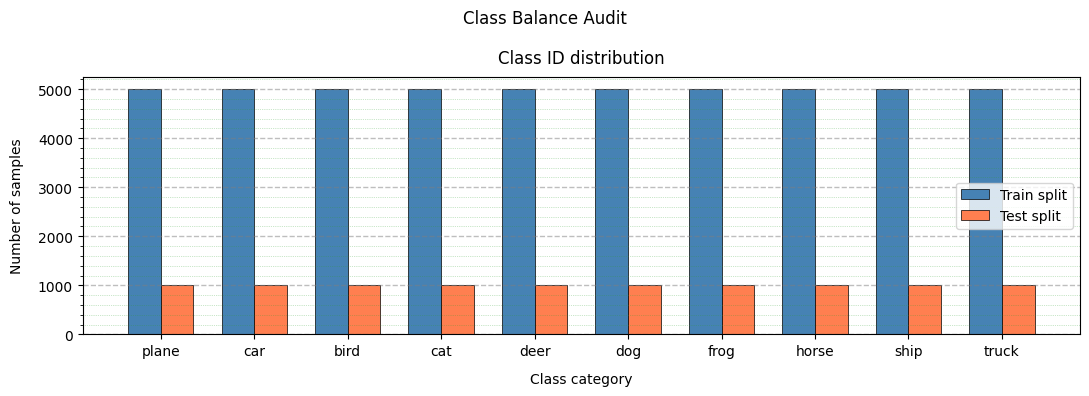

In [6]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
x_indices = np.arange(len(class_names))
bar_width = 0.35

# Solution
_, ax = plt.subplots(figsize=(11, 4))

ax.bar(x_indices - bar_width / 2, train_counts, bar_width,
       label='Train split', color='steelblue', edgecolor='black', linewidth=0.5)
ax.bar(x_indices + bar_width / 2, test_counts, bar_width,
       label='Test split', color='coral', edgecolor='black', linewidth=0.5)

ax.set_xticks(x_indices)
ax.set_xticklabels(class_names, rotation=0, ha='center')
ax.tick_params(axis='x', which='minor', bottom=False, top=False)

ax.grid(axis='y', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
ax.minorticks_on()
ax.grid(axis='y', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Class ID distribution", pad=10, loc='center', color='black')
ax.set_xlabel("Class category", labelpad=10, loc='center', color='black')
ax.set_ylabel("Number of samples", labelpad=10, loc='center', color='black')

ax.legend(frameon=True, loc='center right')
plt.suptitle("Class Balance Audit")

plt.tight_layout()
plt.show()


### Step 1: Data Preparation

In this step, you'll need to prepare the data for training, i.e., you will have to normalize it and encode the labels as one-hot vectors.

In [7]:
# Normalization/Scaling & One-hot encoding

import apps.reporter as rpt
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Input data
is_standard_scaler = False
num_samples_train, height, width, channels = x_train.shape
num_samples_test = x_test.shape[0]

# Solution
scaler = StandardScaler() if is_standard_scaler else MinMaxScaler(feature_range=(0, 1))

# Flatten
x_train_flat = x_train.reshape(num_samples_train, -1)
x_test_flat = x_test.reshape(num_samples_test, -1)

# Scaling / Normalization
x_train_flat = scaler.fit_transform(x_train_flat)
x_test_flat = scaler.transform(x_test_flat)

# Reshape
x_train_n_sc = x_train_flat.reshape(num_samples_train, height, width, channels)
x_test_n_sc = x_test_flat.reshape(num_samples_test, height, width, channels)

# One-hot encoding
y_train_ohe = keras.utils.to_categorical(y_train, num_classes=len(class_names))
y_test_ohe = keras.utils.to_categorical(y_test, num_classes=len(class_names))

rp = rpt.Reporter()
rp.add_item("Preprocessing method", 'Standardization' if is_standard_scaler else 'Min-Max Normalization')
rp.add_item("Train set", f"{len(y_train)} samples")
rp.add_item("Train sample dims", str(x_train_n_sc.shape))
rp.add_item("Train label dims", str(y_train_ohe.shape))
rp.add_item("Train pixel range", f"[{x_train_n_sc.min():.1f}, {x_train_n_sc.max():.1f}], dtype: {x_train_n_sc.dtype}")
rp.add_item("Test set", f"{len(y_test)} samples")
rp.add_item("Test sample dims", str(x_test_n_sc.shape))
rp.add_item("Test label dims", str(y_test_ohe.shape))
rp.add_item("Test pixel range", f"[{x_test_n_sc.min():.1f}, {x_test_n_sc.max():.1f}], dtype: {x_test_n_sc.dtype}")

# Print results
rp.print_pd_report("Report of CIFAR-10 Data Preparation")

Attribute,Result
Preprocessing method,Min-Max Normalization
Train set,50000 samples
Train sample dims,"(50000, 32, 32, 3)"
Train label dims,"(50000, 10)"
Train pixel range,"[0.0, 1.0], dtype: float64"
Test set,10000 samples
Test sample dims,"(10000, 32, 32, 3)"
Test label dims,"(10000, 10)"
Test pixel range,"[0.0, 1.0], dtype: float64"


### Step 2: Building the Classifier

Build the CNN for CIFAR10 classification. For starters, you can use the same network we used in the lesson for the MNIST problem.

Note that, unlike MNIST, the CIFAR-10 images are color (RGB) images.

Model: "cifar10_baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_image (InputLayer)        │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_1_conv (Conv2D)      │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_1_pool               │ (None, 15, 15, 16)     │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_2_conv (Conv2D)      │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv_block_2_pool               │ (None, 6, 6, 32)       │             0 │
│ (MaxPooling2D)                  │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_features (Flatten)      │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier_output (Dense)       │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,618 (64.91 KB)

 Trainable params: 16,618 (64.91 KB)

 Non-trainable params: 0 (0.00 B)

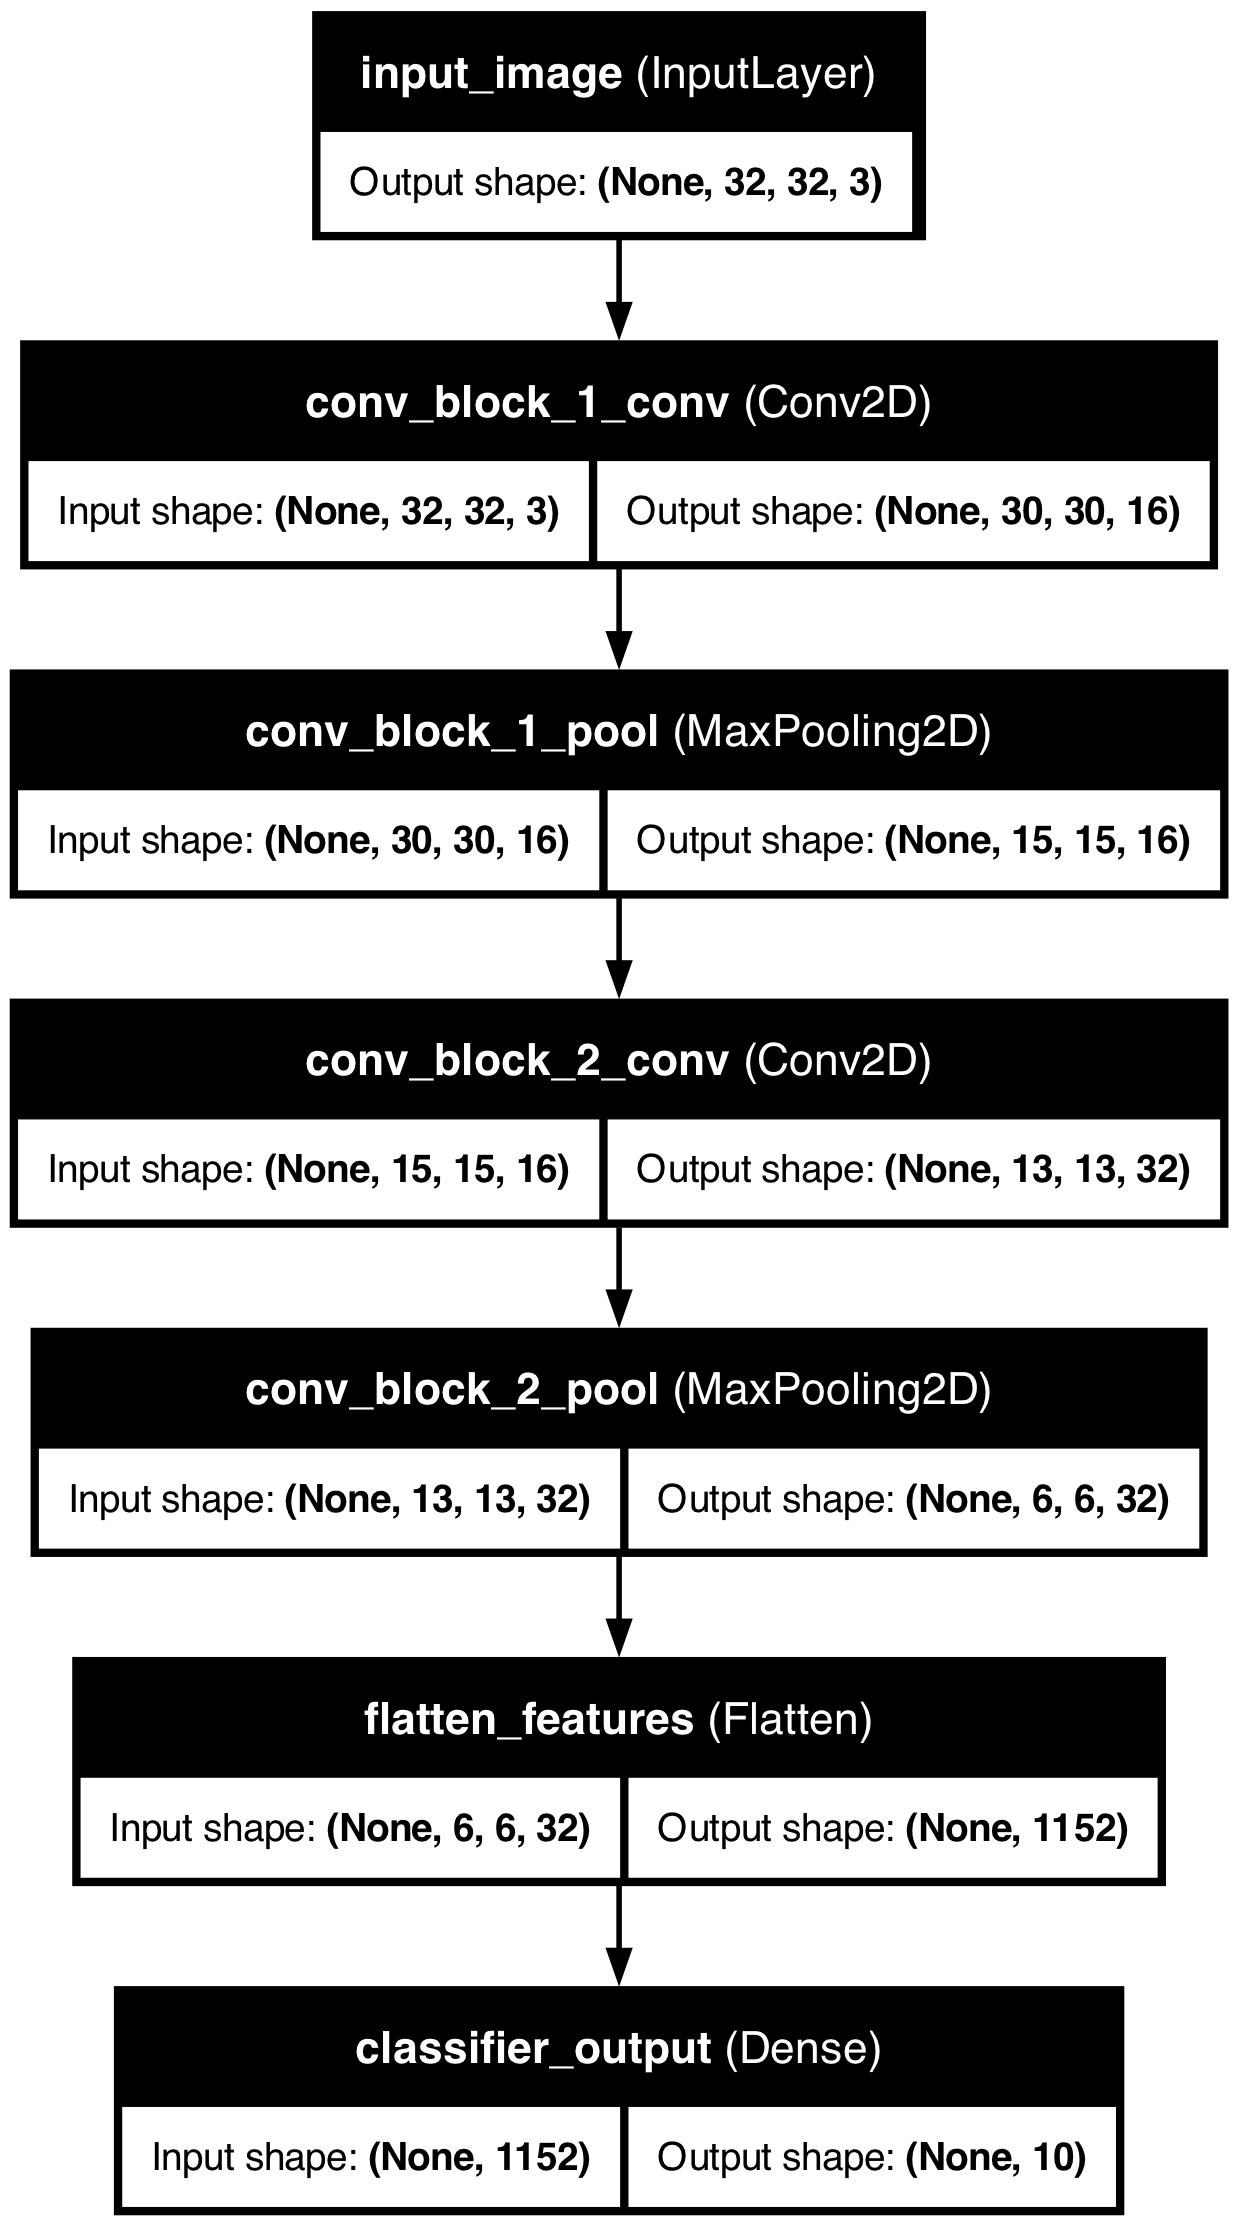

In [8]:
# Build the classifier

from keras import Model
from keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense
from IPython.display import display

# Input data
rng_seed = 42

# Solution
keras.utils.set_random_seed(rng_seed)


# Preparing model
def build_model():
    inputs = Input(shape=example_img.shape, name="input_image")
    net = Conv2D(16, kernel_size=(3, 3), activation="relu", padding="valid", name="conv_block_1_conv")(inputs)
    net = MaxPooling2D(pool_size=(2, 2), name="conv_block_1_pool")(net)
    net = Conv2D(32, kernel_size=(3, 3), activation="relu", padding="valid", name="conv_block_2_conv")(net)
    net = MaxPooling2D(pool_size=(2, 2), name="conv_block_2_pool")(net)
    net = Flatten(name="flatten_features")(net)
    outputs = Dense(len(class_names), activation="softmax", name="classifier_output")(net)
    return Model(inputs=inputs, outputs=outputs, name="cifar10_baseline_cnn")


model = build_model()

# Print results
model.summary()
# Show the model architecture summary
try:
    display(keras.utils.plot_model(model, to_file=f"{folder_name}/model.png", show_shapes=True, show_layer_names=True))
except Exception:
    pass

### Step 3: Training

Compile the model and train it.

In [9]:
# Training

import importlib
import keras
import apps.main as mn
import apps.reporter as rpt

importlib.reload(mn)
importlib.reload(rpt)

# Input data
learning_rate = 0.001
epochs = 25
batch_size = 128
validation_split = 0.1

# Solution
optimizer = keras.optimizers.Adam(learning_rate=learning_rate)
# for testing/comparing
# optimizer = keras.optimizers.SGD(learning_rate=learning_rate)

# Compile the model
model.compile(optimizer=optimizer, loss="categorical_crossentropy", metrics=["accuracy"])

# Train the model
history = model.fit(x_train_n_sc, y_train_ohe, epochs=epochs, batch_size=batch_size,
                    validation_split=validation_split, verbose=0, callbacks=[mn.TqdmProgressCallback(epochs)])

rp = rpt.Reporter()
rp.tolerance = 4
rp.add_item("Model Architecture", "Baseline CNN (Conv2D 16 -> MaxPool -> Conv2D 32 -> MaxPool -> Dense 10)")
rp.add_item("Trainable Parameters", f"{model.count_params():,}")
rp.add_item("Loss Function", "Categorical Cross-Entropy (CCE)")
rp.add_item("Optimizer", "Adam")
rp.add_item("Learning Rate", rp.format_value(learning_rate))
rp.add_item("Batch Size", str(batch_size))
rp.add_item("Epochs", str(epochs))
rp.add_item("Initial Train Loss", rp.format_value(history.history['loss'][0]))
rp.add_item("Final Train Loss", rp.format_value(history.history['loss'][-1]))
rp.add_item("Final Validation Loss", rp.format_value(history.history['val_loss'][-1]))
rp.add_item("Initial Train Accuracy", rp.format_value(history.history['accuracy'][0]))
rp.add_item("Final Train Accuracy", rp.format_value(history.history['accuracy'][-1]))
rp.add_item("Final Validation Accuracy", rp.format_value(history.history['val_accuracy'][-1]))

# Print results
rp.print_pd_report("Report of CIFAR-10 Baseline CNN Training")


Total training:   0%|          | 0/25 [00:00<?, ?it/s]

Epoch: 1, Loss: 1.7142, Accuracy: 0.3831, Status: 4.00%
Epoch: 2, Loss: 1.4082, Accuracy: 0.4992, Status: 8.00%
Epoch: 3, Loss: 1.3126, Accuracy: 0.5395, Status: 12.00%
Epoch: 4, Loss: 1.2515, Accuracy: 0.5636, Status: 16.00%
Epoch: 5, Loss: 1.1937, Accuracy: 0.5869, Status: 20.00%
Epoch: 6, Loss: 1.1568, Accuracy: 0.5978, Status: 24.00%
Epoch: 7, Loss: 1.1223, Accuracy: 0.6110, Status: 28.00%
Epoch: 8, Loss: 1.0904, Accuracy: 0.6236, Status: 32.00%
Epoch: 9, Loss: 1.0656, Accuracy: 0.6318, Status: 36.00%
Epoch: 10, Loss: 1.0366, Accuracy: 0.6423, Status: 40.00%
Epoch: 11, Loss: 1.0140, Accuracy: 0.6512, Status: 44.00%
Epoch: 12, Loss: 0.9975, Accuracy: 0.6566, Status: 48.00%
Epoch: 13, Loss: 0.9847, Accuracy: 0.6597, Status: 52.00%
Epoch: 14, Loss: 0.9622, Accuracy: 0.6678, Status: 56.00%
Epoch: 15, Loss: 0.9488, Accuracy: 0.6732, Status: 60.00%
Epoch: 16, Loss: 0.9350, Accuracy: 0.6770, Status: 64.00%
Epoch: 17, Loss: 0.9267, Accuracy: 0.6809, Status: 68.00%
Epoch: 18, Loss: 0.9184, 

Attribute,Result
Model Architecture,Baseline CNN (Conv2D 16 -> MaxPool -> Conv2D 32 -> MaxPool -> Dense 10)
Trainable Parameters,"16,618"
Loss Function,Categorical Cross-Entropy (CCE)
Optimizer,Adam
Learning Rate,0.0010
Batch Size,128
Epochs,25
Initial Train Loss,1.7142
Final Train Loss,0.8559
Final Validation Loss,0.9579


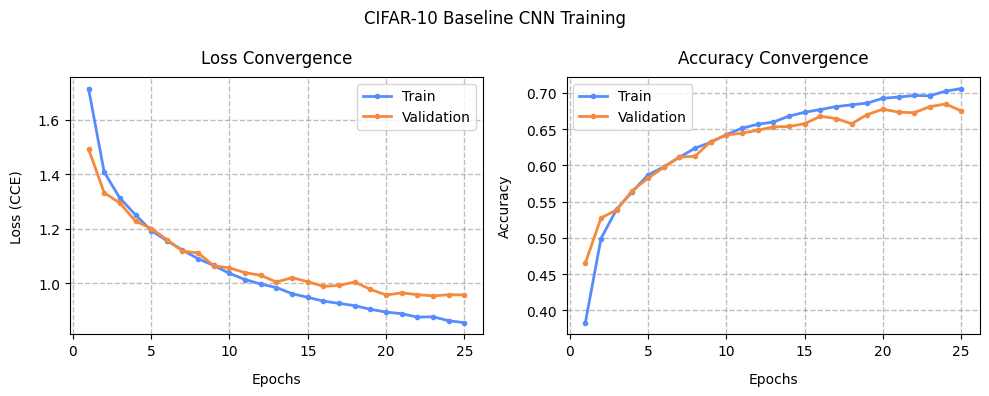

In [10]:
# Graphic results

import matplotlib.pyplot as plt

# Input data
array_x = range(1, epochs + 1)
array_y00 = history.history['loss']
array_y01 = history.history['val_loss']
array_y10 = history.history['accuracy']
array_y11 = history.history['val_accuracy']

# Solution
_, axes = plt.subplots(1, 2, figsize=(10, 4))

ax = axes[0]
ax.plot(array_x, array_y00, ls='-', marker='.', linewidth=2.0, label='Train')
ax.plot(array_x, array_y01, ls='-', marker='.', linewidth=2.0, label='Validation')
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Loss Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epochs", labelpad=10, loc='center', color='black')
ax.set_ylabel("Loss (CCE)", labelpad=10, loc='center', color='black')
ax.legend()

ax = axes[1]
ax.plot(array_x, array_y10, ls='-', marker='.', linewidth=2.0, label='Train')
ax.plot(array_x, array_y11, ls='-', marker='.', linewidth=2.0, label='Validation')
ax.grid(axis='both', visible=True, which='major', ls='--', linewidth=1.0, color='tab:gray')
# ax.minorticks_on()
# ax.grid(axis='both', visible=True, which='minor', ls=':', linewidth=0.5, color='tab:green')
ax.set_title("Accuracy Convergence", pad=10, loc='center', color='black')
ax.set_xlabel("Epochs", labelpad=10, loc='center', color='black')
ax.set_ylabel("Accuracy", labelpad=10, loc='center', color='black')
ax.legend()

plt.suptitle(f"CIFAR-10 Baseline CNN Training")

plt.tight_layout()
plt.show()

### Step 4: Evaluation

In this step, you have to calculate the accuracies and visualize some random samples. For the evaluation, you are going to use the test split from the dataset.

In [11]:
# Evaluation

import importlib
import numpy as np
import apps.main as mn
import apps.reporter as rpt
from apps.reporter import Reporter

importlib.reload(mn)

# Input data

# Solution
# Check the overall stats
ev_loss, ev_accuracy = model.evaluate(x_test_n_sc, y_test_ohe, verbose=0)

rp = rpt.Reporter()
rp.tolerance = 4
rp.add_item("Test loss", rp.format_value(ev_loss))
rp.add_item("Test metric", rp.format_value(ev_accuracy))

# Compute the labels and the predictions as sparse values
y_pred_probs = model.predict(x_test_n_sc, verbose=0, callbacks=[mn.TqdmProgressCallback()])
y_probs = np.max(y_pred_probs, axis=1)
y_pred = np.argmax(y_pred_probs, axis=1)
y_true = np.argmax(y_test_ohe, axis=1)

# Compute and print the accuracy for each class
classes_comparison = []
for class_id, class_name in classes.items():
    y_true_binary = (y_true == class_id).astype(int)
    y_pred_binary = (y_pred == class_id).astype(int)
    y_prob_binary = y_pred_probs[:, class_id]
    # form unique report
    classes_comparison.append((f"Metrics: {class_name}",
                               mn.calc_class_metrics(y_true_binary, y_pred_binary, y_prob_binary,
                                                     is_print=False, is_charts=False)))

# Print results
rp.print_pd_report("The overall stats")
_ = mn.calc_class_metrics(y_true, y_pred, caption="Global Classification Metrics")

Reporter.print_concat_pd_reports(classes_comparison, "Comparative Per-Class Classification Performance")

Predicting:   0%|          | 0/313 [00:00<?, ?it/s]

Attribute,Result
Test loss,0.9926
Test metric,0.6638


Attribute,Result
Accuracy (Точність),0.6638
Precision (Влучність),0.6684
Recall (Повнота),0.6638
F1-score,0.6616


              precision    recall  f1-score   support

           0       0.70      0.70      0.70      1000
           1       0.88      0.64      0.74      1000
           2       0.54      0.54      0.54      1000
           3       0.55      0.42      0.48      1000
           4       0.61      0.66      0.63      1000
           5       0.56      0.60      0.58      1000
           6       0.78      0.72      0.75      1000
           7       0.69      0.72      0.71      1000
           8       0.70      0.82      0.76      1000
           9       0.67      0.83      0.74      1000

    accuracy                           0.66     10000
   macro avg       0.67      0.66      0.66     10000
weighted avg       0.67      0.66      0.66     10000



,Confusion Matrix,Accuracy (Точність),Precision (Влучність),Recall (Повнота),F1-score,Receiver Operating Characteristic (ROC-AUC),Average Precision (AP)
Metrics: plane,[[8703 297] [ 301 699]],0.9402,0.7018,0.6990,0.7004,0.9535,0.7781
Metrics: car,[[8911 89] [ 365 635]],0.9546,0.8771,0.6350,0.7367,0.9748,0.8597
Metrics: bird,[[8533 467] [ 462 538]],0.9071,0.5353,0.5380,0.5367,0.8913,0.5780
Metrics: cat,[[8664 336] [ 582 418]],0.9082,0.5544,0.4180,0.4766,0.8863,0.5231
Metrics: deer,[[8589 411] [ 344 656]],0.9245,0.6148,0.6560,0.6347,0.9337,0.6730
Metrics: dog,[[8521 479] [ 396 604]],0.9125,0.5577,0.6040,0.5799,0.9217,0.6220
Metrics: frog,[[8797 203] [ 282 718]],0.9515,0.7796,0.7180,0.7475,0.9681,0.8350
Metrics: horse,[[8678 322] [ 277 723]],0.9401,0.6919,0.7230,0.7071,0.9566,0.7954
Metrics: ship,[[8658 342] [ 183 817]],0.9475,0.7049,0.8170,0.7568,0.9726,0.8554
Metrics: truck,[[8584 416] [ 170 830]],0.9414,0.6661,0.8300,0.7391,0.9669,0.8229


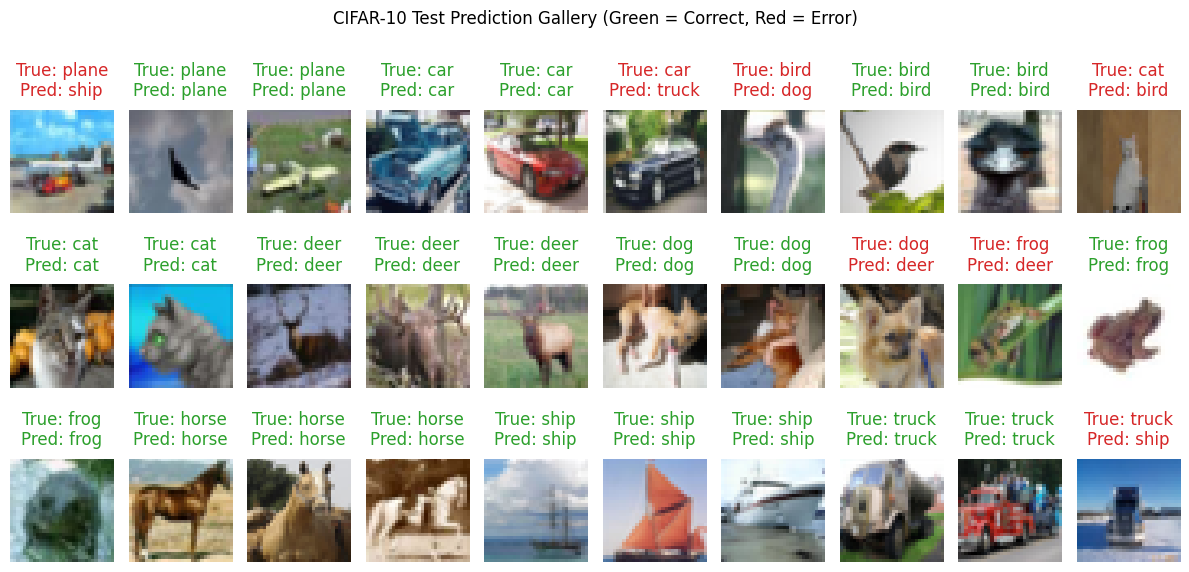

In [12]:
# Graphic results

import math
import numpy as np
import matplotlib.pyplot as plt

# Input data
n_images_per_class = 3
n_img_cols = 10

# Solution
analysis_samples = []
analysis_colors = []
# preparing set of images for analysis
for class_id in range(len(classes)):
    # filter indexes of the necessary class
    class_indices = np.where(y_test == class_id)[0]
    # get 3 random images
    random_indices = np.random.choice(class_indices, size=n_images_per_class, replace=False)
    # add images to list
    for idx in random_indices:
        # add image
        key = f"True: {classes[y_true[idx]]}\nPred: {classes[y_pred[idx]]}"
        value = x_test[idx]
        analysis_samples.append((key, value))

        # add color
        is_correct = (y_true[idx] == y_pred[idx])
        title_color = 'tab:green' if is_correct else 'tab:red'
        analysis_colors.append(title_color)

images_list = analysis_samples
n_img_rows = math.ceil(len(images_list) / n_img_cols)

_, axes = plt.subplots(n_img_rows, n_img_cols, figsize=(12, 2 * n_img_rows))
axes_list = np.array(axes).flatten()

for idx, (img_name, img_data) in enumerate(images_list):
    ax = axes_list[idx]
    ax.set_title(img_name, pad=10, loc='center', color=analysis_colors[idx])
    if len(img_data.shape) == 3:
        ax.imshow(img_data)
    else:
        ax.imshow(img_data, cmap='gray')
    ax.axis(False)

# remove empty charts
for idx in range(len(images_list), len(axes_list)):
    axes_list[idx].remove()

# Plot
plt.suptitle("CIFAR-10 Test Prediction Gallery (Green = Correct, Red = Error)", y=1.0)
plt.tight_layout()
plt.show()


### Questions
* What is the overall accuracy of the classifier?
* What modifications would you do in order to improve the classification accuracy?
* Make **one** modification (that you think can help) and train the classifier again. Does the accuracy improve?
* Compare the training and the validation accuracy. What do you observe?

### Conclusion

1. The baseline CNN achieves an overall test accuracy of 66.38% (0.6638) with a test loss of 0.9926 (Precision: 0.6684, Recall: 0.6638, F1-score: 0.6616) across the 10,000 unseen test samples. On the training set, it achieved 70.58% accuracy and 67.52% on the validation split.
2. **Padding (padding="same")** - avoid clipping image borders during convolutions to retain edge details. **Better Activation Functions (ELU / LeakyReLU)** - replace standard ReLU to prevent dying neurons on negative values. **Standardization Instead of Scaling (StandardScaler)** - center pixel values around zero, which helps the optimizer converge faster and more reliably. **Additional Hidden Layer (Dense)** - add an intermediate fully-connected layer to better combine extracted features before final classification.
Fewer Epochs: Reduce training time (from 25 down to 10 epochs) to prevent the model from overfitting.
3. In **Modification.ipynb**, we introduced **padding="same"**, **ELU** convolutional activations, **LeakyReLU** dense activation, **he_normal** kernel initialization, input feature **standardization**, an intermediate **Dense(16)** layer, and capped training at **10 epochs** (expanding trainable parameters from 16,618 to 38,042). Outcome: Yes, the test accuracy improved, rising from 66.38% to 67.41% (+1.03%), while test loss decreased from 0.9926 to 0.9834. Concurrently, training accuracy jumped from 70.58% to 74.62% (+4.04%), and validation accuracy improved from 67.52% to 68.48% (+0.96%).
4. **Widening Overfitting Gap** - in the baseline model, the gap between training and validation accuracy was around 3%, whereas in the modified model it expanded to 6.1% (Train 74.62% vs. Val 68.48%). The model starts overfitting even with fewer epochs.
**Low Image Resolution (32×32)** - the images are inherently small and blurry, making fine textural discrimination difficult (especially for animals like cats, dogs, and birds, which exhibit the lowest accuracy). This is the primary physical bottleneck for a shallow CNN. **Diminishing Returns on Test Data** - adding capacity and tuning hyperparameters yields rapid performance gains on the training set, but test accuracy improves only by a fraction. A simple network memorizes training samples much faster than it learns to generalize to unseen data.